# B4 — APTOS2019

The B1-equivalent quarantine (Q) and removal control (R) test whether excluding train-only, exactly duplicated images with conflicting labels affects performance.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

The B4 runner and selection/cache scripts were external. The B1 component matches [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/3a563c67fef82454ce2ed34858615bd456424a13/novelty/foundation_adaptation.py), but the historical B4 orchestration has no tracked entry point.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B4', 'APTOS2019'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = 'fef0017f2336f1ec7909e14005335471533dffc1067e00ba4d57946dcab1d5ed'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate. For B4, set `DR_RECORDED_RUN_ID` to `APTOS2019_B4_Q` or `APTOS2019_B4_R` when supplying a checkpoint.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B4-Q recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2880, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "b4": {
    "arm": "B4-Q",
    "augmentation_source_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "b1_source_sha256": "2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300",
    "common_sha256": "8451ecd9c4f462a0704a3a4c4c900bbde35878ed164854939e6c58bfca98c0a4",
    "original_manifest_sha256": "73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854",
    "runner_sha256": "99cffa0e8159054191e5a1aada0fdf4e63d162fd822c49162a2acaf9685325bc",
    "sampling": "B1 seeded permutation only; no B3 sampler",
    "scheduler": "none, matching B1",
    "schema": "b4-b1-equivalent-v1",
    "selection_removed_groups": 24,
    "selection_removed_rows": 50,
    "selection_sha256": "1444191fe6d8f5b53ef4b95f5bca137bfa8f08aa4a0a4ecd6218585a944ae9b2",
    "smoke_report_sha256": "9cb5d2865701f2ed638fccd90cd62d947e91b65282c3aecf6faf1b9b631c95c2",
    "validation_cache": {
      "audit_sha256": "debdaedef14de3439b89fb3ad921ae5a3321f142c31776d4771bec935b17144c",
      "metadata_sha256": "f8a0d8acfc6c4e6007c2f591a0f3707f6829e70345d43d0fb936dfe192fdce6b",
      "runner_sha256": "99cffa0e8159054191e5a1aada0fdf4e63d162fd822c49162a2acaf9685325bc",
      "summary_sha256": "06ccb87c6a7c140fa6b9ff06080f8b928b34b44cc7ad3864ae6711c369938eed"
    },
    "validation_original_rows": 366
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.791808 | 0.719097 | 0.369956 | 0.661405 | 0.658068 | 0.4625 |
| 2 | 0.52704 | 0.797569 | 0.494425 | 0.755668 | 0.814835 | 0.295833 |
| 3 | 0.463403 | 0.821528 | 0.582457 | 0.795799 | 0.848858 | 0.256944 |
| 4 | 0.415401 | 0.845139 | 0.676545 | 0.833152 | 0.879021 | 0.219444 |
| 5 | 0.380623 | 0.855556 | 0.694728 | 0.845513 | 0.892522 | 0.202083 |
| 6 | 0.347646 | 0.867014 | 0.730543 | 0.861007 | 0.903706 | 0.184722 |
| 7 | 0.314861 | 0.884375 | 0.762933 | 0.879227 | 0.918329 | 0.159722 |
| 8 | 0.286705 | 0.89375 | 0.788032 | 0.890331 | 0.927743 | 0.145139 |
| 9 | 0.25165 | 0.907639 | 0.818856 | 0.905224 | 0.935019 | 0.128472 |
| 10 | 0.21266 | 0.923611 | 0.85097 | 0.921845 | 0.946 | 0.10625 |
| 11 | 0.186739 | 0.938889 | 0.8794 | 0.93761 | 0.956862 | 0.0850694 |
| 12 | 0.160297 | 0.945486 | 0.892271 | 0.94474 | 0.96263 | 0.075 |
| 13 | 0.137864 | 0.954861 | 0.911366 | 0.954467 | 0.971089 | 0.0604167 |
| 14 | 0.114082 | 0.965625 | 0.931121 | 0.965347 | 0.979069 | 0.0447917 |
| 15 | 0.0909431 | 0.973611 | 0.946917 | 0.973411 | 0.98348 | 0.0350694 |
| 16 | 0.0700967 | 0.983681 | 0.967145 | 0.983614 | 0.991937 | 0.0197917 |
| 17 | 0.060005 | 0.985417 | 0.969091 | 0.985314 | 0.992584 | 0.0177083 |
| 18 | 0.0503526 | 0.988194 | 0.975501 | 0.988133 | 0.992788 | 0.015625 |
| 19 | 0.0347998 | 0.991667 | 0.981505 | 0.991635 | 0.995733 | 0.0100694 |
| 20 | 0.0282526 | 0.991667 | 0.980872 | 0.991649 | 0.995416 | 0.0104167 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.616421 | 0.751366 | 0.385961 | 0.694142 | 0.793234 | 0.346995 |
| 2 | 0.557801 | 0.789617 | 0.54611 | 0.762609 | 0.845132 | 0.284153 |
| 3 | 0.523609 | 0.79235 | 0.566759 | 0.771998 | 0.858902 | 0.273224 |
| 4 | 0.508156 | 0.806011 | 0.602536 | 0.790134 | 0.878223 | 0.254098 |
| 5 | 0.492978 | 0.803279 | 0.624765 | 0.797465 | 0.884009 | 0.248634 |
| 6 | 0.493391 | 0.806011 | 0.62029 | 0.797052 | 0.879782 | 0.251366 |
| 7 | 0.500223 | 0.806011 | 0.623727 | 0.799239 | 0.882379 | 0.248634 |
| 8 | 0.519316 | 0.808743 | 0.675364 | 0.813545 | 0.882202 | 0.262295 |
| 9 | 0.507473 | 0.822404 | 0.681104 | 0.823024 | 0.897632 | 0.224044 |
| 10 | 0.518592 | 0.819672 | 0.663887 | 0.817273 | 0.893971 | 0.226776 |
| 11 | 0.542898 | 0.819672 | 0.688319 | 0.823274 | 0.893995 | 0.234973 |
| 12 | 0.547269 | 0.819672 | 0.669477 | 0.820223 | 0.898528 | 0.229508 |
| 13 | 0.569394 | 0.81694 | 0.661345 | 0.816956 | 0.892062 | 0.240437 |
| 14 | 0.558618 | 0.819672 | 0.664797 | 0.819496 | 0.902214 | 0.226776 |
| 15 | 0.586599 | 0.814208 | 0.667423 | 0.815383 | 0.899715 | 0.23224 |
| 16 | 0.665326 | 0.819672 | 0.685664 | 0.822453 | 0.901477 | 0.224044 |
| 17 | 0.681462 | 0.806011 | 0.65528 | 0.808102 | 0.896919 | 0.240437 |
| 18 | 0.715904 | 0.803279 | 0.651629 | 0.806188 | 0.894927 | 0.245902 |
| 19 | 0.738938 | 0.819672 | 0.680302 | 0.821458 | 0.90018 | 0.226776 |
| 20 | 0.796525 | 0.819672 | 0.682917 | 0.821775 | 0.898362 | 0.229508 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 611.989 | 0.827418 | 599.52 | 0.355321 | 4.70596 | 442.34 | 2665480192 | 2891997184 | 59 | 32 | 1 |
| 2 | 601.994 | 0.804282 | 589.86 | 0.3356 | 4.7841 | 455.064 | 2665480192 | 2891997184 | 47 | 30 | 1 |
| 3 | 605.736 | 0.806538 | 593.905 | 0.336823 | 4.75455 | 453.791 | 2665480192 | 3009531904 | 43 | 33 | 2 |
| 4 | 596.925 | 0.869411 | 584.761 | 0.343922 | 4.82472 | 420.975 | 2665480192 | 3009531904 | 34 | 37 | 2 |
| 5 | 596.217 | 0.888251 | 583.9 | 0.340697 | 4.83046 | 412.046 | 2665480192 | 3009531904 | 39 | 33 | 8 |
| 6 | 607.892 | 0.811348 | 595.834 | 0.340252 | 4.73768 | 451.101 | 2665480192 | 3009531904 | 38 | 33 | 10 |
| 7 | 599.131 | 0.81204 | 586.741 | 0.341606 | 4.80696 | 450.717 | 2665480192 | 3009531904 | 41 | 30 | 13 |
| 8 | 606.066 | 0.816019 | 593.917 | 0.344178 | 4.75196 | 448.519 | 2665480192 | 3009531904 | 30 | 40 | 9 |
| 9 | 613.231 | 0.806557 | 601.09 | 0.337373 | 4.69643 | 453.781 | 2665480192 | 3009531904 | 34 | 31 | 15 |
| 10 | 618.337 | 0.809862 | 606.32 | 0.338215 | 4.65765 | 451.929 | 2665480192 | 3009531904 | 37 | 29 | 15 |
| 11 | 608.331 | 0.80471 | 596.038 | 0.335596 | 4.73426 | 454.822 | 2665480192 | 3009531904 | 30 | 36 | 19 |
| 12 | 609.258 | 0.894386 | 597.156 | 0.340597 | 4.72706 | 409.219 | 2665480192 | 3009531904 | 34 | 32 | 20 |
| 13 | 610.203 | 0.8083 | 597.969 | 0.337271 | 4.71974 | 452.802 | 2665480192 | 3009531904 | 35 | 32 | 19 |
| 14 | 598.954 | 0.808627 | 586.79 | 0.339278 | 4.80838 | 452.619 | 2665480192 | 3009531904 | 27 | 39 | 18 |
| 15 | 602.457 | 0.813248 | 590.211 | 0.343469 | 4.78043 | 450.047 | 2665480192 | 3009531904 | 30 | 38 | 22 |
| 16 | 621.945 | 0.806866 | 609.451 | 0.335751 | 4.63063 | 453.607 | 2665480192 | 3009531904 | 36 | 30 | 24 |
| 17 | 620.262 | 0.812862 | 608.07 | 0.3419 | 4.6432 | 450.261 | 2665480192 | 3009531904 | 33 | 38 | 23 |
| 18 | 603.935 | 0.806548 | 591.67 | 0.334198 | 4.76873 | 453.786 | 2665480192 | 3009531904 | 32 | 40 | 31 |
| 19 | 595.386 | 0.807212 | 583.327 | 0.337979 | 4.8372 | 453.412 | 2665480192 | 3009531904 | 32 | 34 | 33 |
| 20 | 613.231 | 0.80499 | 601.146 | 0.336082 | 4.69644 | 454.664 | 2665480192 | 3009531904 | 34 | 32 | 37 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 5 | True |
| 6 | 1e-05 | 0.001 | — | 5 | False |
| 7 | 1e-05 | 0.001 | — | 5 | False |
| 8 | 1e-05 | 0.001 | — | 8 | True |
| 9 | 1e-05 | 0.001 | — | 9 | True |
| 10 | 1e-05 | 0.001 | — | 9 | False |
| 11 | 1e-05 | 0.001 | — | 11 | True |
| 12 | 1e-05 | 0.001 | — | 11 | False |
| 13 | 1e-05 | 0.001 | — | 11 | False |
| 14 | 1e-05 | 0.001 | — | 11 | False |
| 15 | 1e-05 | 0.001 | — | 11 | False |
| 16 | 1e-05 | 0.001 | — | 11 | False |
| 17 | 1e-05 | 0.001 | — | 11 | False |
| 18 | 1e-05 | 0.001 | — | 11 | False |
| 19 | 1e-05 | 0.001 | — | 11 | False |
| 20 | 1e-05 | 0.001 | — | 11 | False |

## B4-Q best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 11 | 0.819672 | 0.688319 | 0.823274 | 0.893995 | 0.234973 | 300 | 66 | 30 | 36 |

Frozen validation only. The selected checkpoint SHA-256 is `fef0017f2336f1ec7909e14005335471533dffc1067e00ba4d57946dcab1d5ed`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 175 | 5 | 0 | 0 | 0 |
| 1 | 1 | 23 | 10 | 0 | 1 |
| 2 | 0 | 13 | 73 | 9 | 6 |
| 3 | 0 | 0 | 4 | 11 | 5 |
| 4 | 0 | 2 | 8 | 2 | 18 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 97.2222 | 2.77778 | 0 | 0 | 0 |
| 1 | 2.85714 | 65.7143 | 28.5714 | 0 | 2.85714 |
| 2 | 0 | 12.8713 | 72.2772 | 8.91089 | 5.94059 |
| 3 | 0 | 0 | 20 | 55 | 25 |
| 4 | 0 | 6.66667 | 26.6667 | 6.66667 | 60 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994318 | 0.972222 | 0.983146 | 180 | 175 |
| 1 | 0.534884 | 0.657143 | 0.589744 | 35 | 23 |
| 2 | 0.768421 | 0.722772 | 0.744898 | 101 | 73 |
| 3 | 0.5 | 0.55 | 0.52381 | 20 | 11 |
| 4 | 0.6 | 0.6 | 0.6 | 30 | 18 |

Minority-grade predictions on the diagonal were grade 1 23/35, grade 3 11/20. The largest off-diagonal counts were 2 → 1 (13), 1 → 2 (10), 2 → 3 (9). The matrix gives 49 adjacent errors and 17 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B4_Q_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B4_Q_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

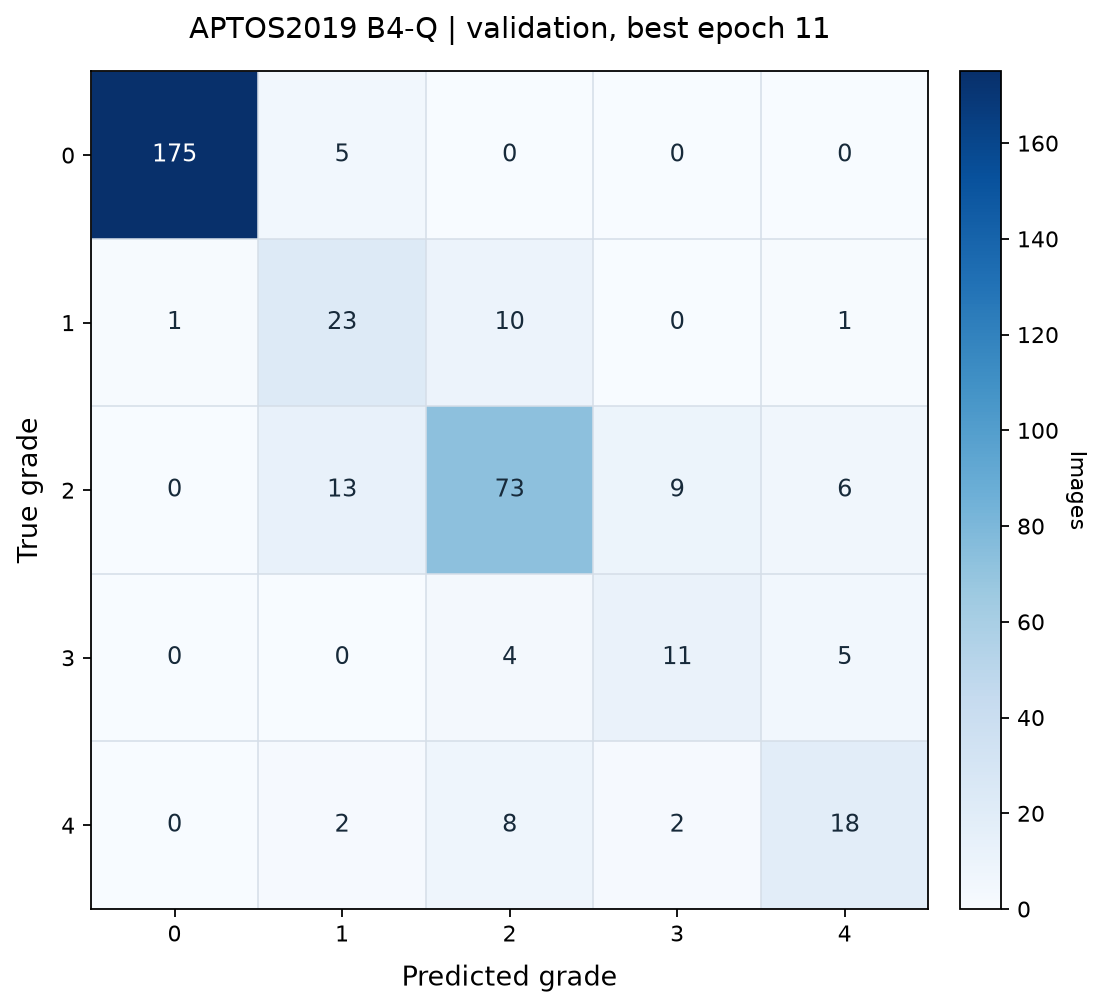

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B4_Q_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

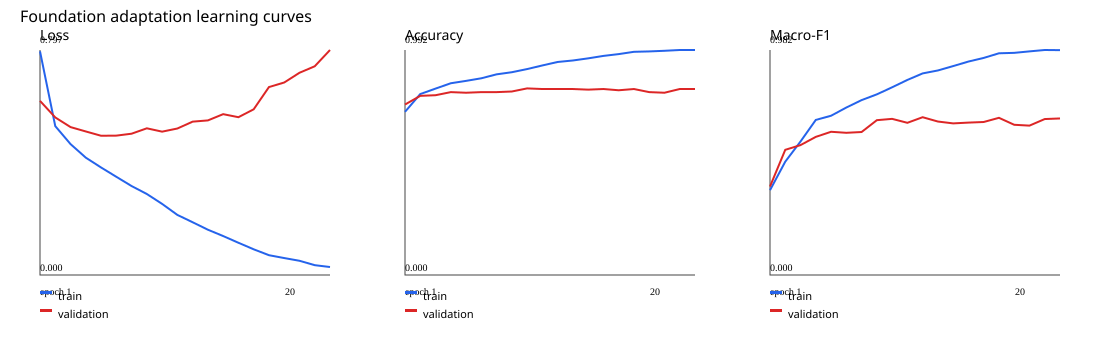

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B4_Q_learning_curves.svg')))

## B4-R recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2880, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "b4": {
    "arm": "B4-R",
    "augmentation_source_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "b1_source_sha256": "2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300",
    "common_sha256": "8451ecd9c4f462a0704a3a4c4c900bbde35878ed164854939e6c58bfca98c0a4",
    "original_manifest_sha256": "73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854",
    "runner_sha256": "99cffa0e8159054191e5a1aada0fdf4e63d162fd822c49162a2acaf9685325bc",
    "sampling": "B1 seeded permutation only; no B3 sampler",
    "scheduler": "none, matching B1",
    "schema": "b4-b1-equivalent-v1",
    "selection_removed_groups": 27,
    "selection_removed_rows": 50,
    "selection_sha256": "6bb900e0ed4bd948a30cb293f332eecc8a7a498b56662c8d1e1851bf2f3e4780",
    "smoke_report_sha256": "07bf57d1be0e65678fd0bd2847acd3f4cdf5538eb21ab512d27384caf3559a42",
    "validation_cache": {
      "audit_sha256": "debdaedef14de3439b89fb3ad921ae5a3321f142c31776d4771bec935b17144c",
      "metadata_sha256": "f8a0d8acfc6c4e6007c2f591a0f3707f6829e70345d43d0fb936dfe192fdce6b",
      "runner_sha256": "99cffa0e8159054191e5a1aada0fdf4e63d162fd822c49162a2acaf9685325bc",
      "summary_sha256": "06ccb87c6a7c140fa6b9ff06080f8b928b34b44cc7ad3864ae6711c369938eed"
    },
    "validation_original_rows": 366
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.811054 | 0.701389 | 0.34952 | 0.63645 | 0.599388 | 0.517014 |
| 2 | 0.536304 | 0.795139 | 0.485704 | 0.752131 | 0.810887 | 0.299306 |
| 3 | 0.469126 | 0.818403 | 0.585966 | 0.794916 | 0.851706 | 0.257986 |
| 4 | 0.425233 | 0.836806 | 0.653924 | 0.823596 | 0.877388 | 0.226389 |
| 5 | 0.385016 | 0.852083 | 0.697092 | 0.844203 | 0.89403 | 0.204514 |
| 6 | 0.354624 | 0.866319 | 0.722881 | 0.858635 | 0.9007 | 0.187153 |
| 7 | 0.321439 | 0.879167 | 0.755282 | 0.873728 | 0.910546 | 0.169097 |
| 8 | 0.290737 | 0.889931 | 0.77777 | 0.886 | 0.925559 | 0.149653 |
| 9 | 0.263299 | 0.904167 | 0.809572 | 0.901702 | 0.933819 | 0.132292 |
| 10 | 0.231454 | 0.920139 | 0.842755 | 0.918327 | 0.947129 | 0.108333 |
| 11 | 0.197516 | 0.934028 | 0.870574 | 0.932921 | 0.957276 | 0.0885417 |
| 12 | 0.17924 | 0.937847 | 0.876806 | 0.936872 | 0.958469 | 0.0847222 |
| 13 | 0.156583 | 0.948264 | 0.898392 | 0.947573 | 0.963765 | 0.0722222 |
| 14 | 0.131563 | 0.955903 | 0.911426 | 0.955491 | 0.972714 | 0.0579861 |
| 15 | 0.107303 | 0.967361 | 0.933706 | 0.967079 | 0.978978 | 0.04375 |
| 16 | 0.0908835 | 0.973611 | 0.948521 | 0.973521 | 0.984493 | 0.0340278 |
| 17 | 0.0882386 | 0.973264 | 0.94687 | 0.973095 | 0.984071 | 0.034375 |
| 18 | 0.0715597 | 0.976389 | 0.951997 | 0.97631 | 0.989794 | 0.0270833 |
| 19 | 0.0567836 | 0.981597 | 0.96188 | 0.981542 | 0.989692 | 0.0232639 |
| 20 | 0.0602674 | 0.980208 | 0.959597 | 0.980202 | 0.987482 | 0.0263889 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.619506 | 0.762295 | 0.431171 | 0.711859 | 0.766842 | 0.352459 |
| 2 | 0.566118 | 0.784153 | 0.516444 | 0.749601 | 0.821476 | 0.300546 |
| 3 | 0.516117 | 0.797814 | 0.561245 | 0.774822 | 0.860644 | 0.26776 |
| 4 | 0.490642 | 0.814208 | 0.648404 | 0.810719 | 0.871324 | 0.256831 |
| 5 | 0.480003 | 0.81694 | 0.636596 | 0.807367 | 0.884511 | 0.237705 |
| 6 | 0.472649 | 0.819672 | 0.647439 | 0.812588 | 0.885947 | 0.234973 |
| 7 | 0.48716 | 0.81694 | 0.643927 | 0.809552 | 0.889411 | 0.23224 |
| 8 | 0.477743 | 0.81694 | 0.672144 | 0.818439 | 0.885781 | 0.245902 |
| 9 | 0.487547 | 0.827869 | 0.707897 | 0.831054 | 0.898937 | 0.221311 |
| 10 | 0.484669 | 0.833333 | 0.691981 | 0.833729 | 0.898362 | 0.218579 |
| 11 | 0.506056 | 0.830601 | 0.704121 | 0.833246 | 0.901622 | 0.215847 |
| 12 | 0.516698 | 0.825137 | 0.666467 | 0.824666 | 0.896595 | 0.226776 |
| 13 | 0.551755 | 0.833333 | 0.701589 | 0.833972 | 0.905609 | 0.20765 |
| 14 | 0.52193 | 0.822404 | 0.679428 | 0.823985 | 0.898011 | 0.226776 |
| 15 | 0.58085 | 0.827869 | 0.69627 | 0.829449 | 0.901054 | 0.218579 |
| 16 | 0.588108 | 0.825137 | 0.684715 | 0.826817 | 0.898223 | 0.226776 |
| 17 | 0.642367 | 0.81694 | 0.665499 | 0.819605 | 0.897723 | 0.237705 |
| 18 | 0.621978 | 0.811475 | 0.673005 | 0.815653 | 0.883595 | 0.254098 |
| 19 | 0.646216 | 0.814208 | 0.681591 | 0.818455 | 0.888826 | 0.248634 |
| 20 | 0.694717 | 0.819672 | 0.677149 | 0.822197 | 0.897549 | 0.23224 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 616.371 | 0.820981 | 603.78 | 0.345714 | 4.67251 | 445.808 | 2665480192 | 2853179392 | 67 | 20 | 2 |
| 2 | 607.066 | 0.801818 | 594.982 | 0.333234 | 4.74413 | 456.463 | 2665480192 | 2950385664 | 55 | 24 | 1 |
| 3 | 610.271 | 0.804723 | 598.338 | 0.335329 | 4.71921 | 454.815 | 2665480192 | 2950385664 | 44 | 30 | 2 |
| 4 | 601.036 | 0.809788 | 588.532 | 0.337843 | 4.79173 | 451.97 | 2665480192 | 2950385664 | 38 | 30 | 4 |
| 5 | 595.404 | 0.817295 | 583.067 | 0.346424 | 4.83705 | 447.819 | 2665480192 | 2950385664 | 39 | 28 | 8 |
| 6 | 602.563 | 0.860356 | 590.239 | 0.343412 | 4.77959 | 425.405 | 2665480192 | 2950385664 | 37 | 29 | 9 |
| 7 | 598.927 | 0.813674 | 586.562 | 0.341523 | 4.8086 | 449.811 | 2665480192 | 2950385664 | 39 | 28 | 11 |
| 8 | 608.59 | 0.80607 | 596.068 | 0.336311 | 4.73225 | 454.055 | 2665480192 | 2950385664 | 31 | 36 | 10 |
| 9 | 606.003 | 0.818261 | 593.937 | 0.344841 | 4.75245 | 447.29 | 2665480192 | 2979569664 | 28 | 35 | 10 |
| 10 | 621.413 | 0.810037 | 609.099 | 0.339884 | 4.6346 | 451.831 | 2665480192 | 2979569664 | 32 | 29 | 11 |
| 11 | 613.574 | 0.889518 | 601.282 | 0.337546 | 4.69381 | 411.459 | 2665480192 | 2979569664 | 28 | 34 | 12 |
| 12 | 613.974 | 0.804697 | 601.952 | 0.336174 | 4.69075 | 454.83 | 2665480192 | 2979569664 | 32 | 32 | 13 |
| 13 | 612.714 | 0.811889 | 600.437 | 0.341137 | 4.7004 | 450.8 | 2665480192 | 2979569664 | 35 | 26 | 18 |
| 14 | 598.317 | 0.806895 | 586.111 | 0.336721 | 4.8135 | 453.59 | 2665480192 | 2979569664 | 31 | 34 | 16 |
| 15 | 604.35 | 0.816368 | 592.163 | 0.34537 | 4.76545 | 448.327 | 2665480192 | 2979569664 | 32 | 31 | 22 |
| 16 | 623.955 | 0.806554 | 611.048 | 0.338526 | 4.61572 | 453.783 | 2665480192 | 2979569664 | 32 | 32 | 21 |
| 17 | 618.624 | 0.807398 | 606.281 | 0.338432 | 4.65549 | 453.308 | 2665480192 | 2979569664 | 29 | 38 | 25 |
| 18 | 606.545 | 0.809397 | 594.392 | 0.340241 | 4.7482 | 452.189 | 2665480192 | 2979569664 | 31 | 38 | 23 |
| 19 | 597.985 | 0.807999 | 585.712 | 0.339404 | 4.81617 | 452.971 | 2665480192 | 2979569664 | 29 | 39 | 23 |
| 20 | 611.59 | 0.792308 | 599.375 | 0.322791 | 4.70904 | 461.942 | 2665480192 | 2979569664 | 33 | 33 | 29 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 4 | False |
| 6 | 1e-05 | 0.001 | — | 4 | False |
| 7 | 1e-05 | 0.001 | — | 4 | False |
| 8 | 1e-05 | 0.001 | — | 8 | True |
| 9 | 1e-05 | 0.001 | — | 9 | True |
| 10 | 1e-05 | 0.001 | — | 9 | False |
| 11 | 1e-05 | 0.001 | — | 9 | False |
| 12 | 1e-05 | 0.001 | — | 9 | False |
| 13 | 1e-05 | 0.001 | — | 9 | False |
| 14 | 1e-05 | 0.001 | — | 9 | False |
| 15 | 1e-05 | 0.001 | — | 9 | False |
| 16 | 1e-05 | 0.001 | — | 9 | False |
| 17 | 1e-05 | 0.001 | — | 9 | False |
| 18 | 1e-05 | 0.001 | — | 9 | False |
| 19 | 1e-05 | 0.001 | — | 9 | False |
| 20 | 1e-05 | 0.001 | — | 9 | False |

## B4-R best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 9 | 0.827869 | 0.707897 | 0.831054 | 0.898937 | 0.221311 | 303 | 63 | 28 | 35 |

Frozen validation only. The selected checkpoint SHA-256 is `b3f01ee530a3e46e61c8a35156ca647134c0994c2bf0b75cd384d0f2b8894242`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 174 | 6 | 0 | 0 | 0 |
| 1 | 1 | 21 | 12 | 0 | 1 |
| 2 | 0 | 12 | 77 | 9 | 3 |
| 3 | 0 | 0 | 2 | 14 | 4 |
| 4 | 0 | 2 | 9 | 2 | 17 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 96.6667 | 3.33333 | 0 | 0 | 0 |
| 1 | 2.85714 | 60 | 34.2857 | 0 | 2.85714 |
| 2 | 0 | 11.8812 | 76.2376 | 8.91089 | 2.9703 |
| 3 | 0 | 0 | 10 | 70 | 20 |
| 4 | 0 | 6.66667 | 30 | 6.66667 | 56.6667 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994286 | 0.966667 | 0.980282 | 180 | 174 |
| 1 | 0.512195 | 0.6 | 0.552632 | 35 | 21 |
| 2 | 0.77 | 0.762376 | 0.766169 | 101 | 77 |
| 3 | 0.56 | 0.7 | 0.622222 | 20 | 14 |
| 4 | 0.68 | 0.566667 | 0.618182 | 30 | 17 |

Minority-grade predictions on the diagonal were grade 1 21/35, grade 3 14/20. The largest off-diagonal counts were 2 → 1 (12), 1 → 2 (12), 4 → 2 (9). The matrix gives 48 adjacent errors and 15 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B4_R_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B4_R_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

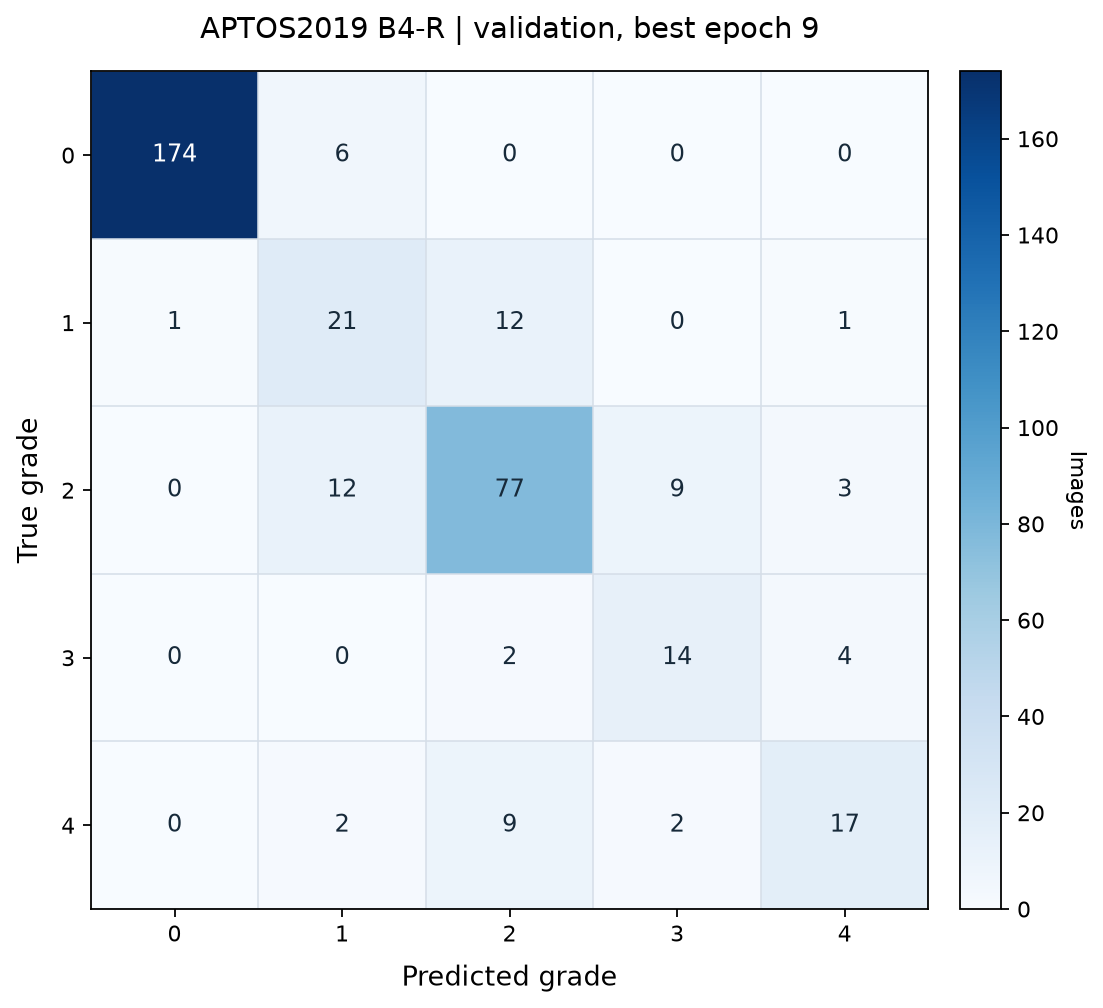

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B4_R_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

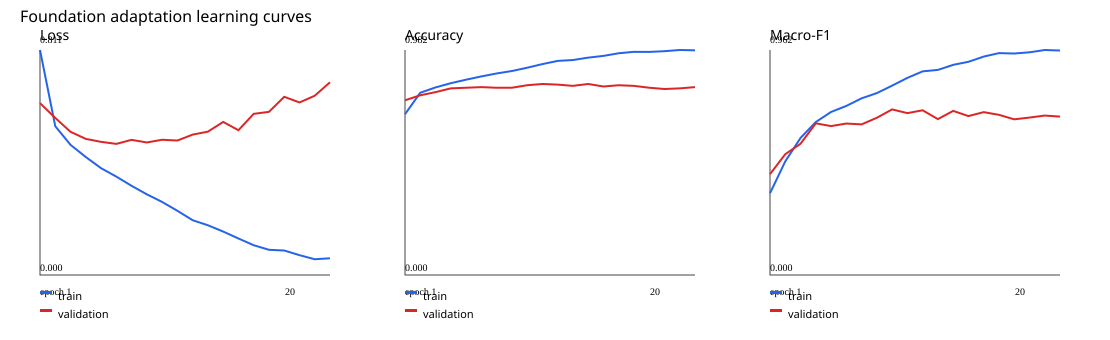

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B4_R_learning_curves.svg')))

## Interpretation and limits

Quarantine Q changed macro-F1 by -0.019578 versus matched removal R. That one validation contrast does not establish a general effect of quarantine.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Execution availability

The original external orchestration and input selection are prerequisites for a historical rerun. The signed-off reporting path reads aggregate evidence only. There is no substitute training cell for these arms.